# 01 · Default model, score cut-off and expected loss

**Business question:** who should we approve, how much risk sits in each part of the book, and can customers afford their repayments?

**Data:** Home Credit Default Risk, `application_train.csv`: one row per loan application. `TARGET = 1` means the customer had payment difficulties, which we treat as **default**.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, OUT, CHARTS = ROOT / "data/raw", ROOT / "data/processed", ROOT / "reports/charts"

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.4f}".format)
print("Project root:", ROOT)

Project root: c:\Users\lamid\Documents\banking-credit-analytics


In [12]:
cols = ["SK_ID_CURR", "TARGET", "NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
        "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "DAYS_BIRTH", "DAYS_EMPLOYED",
        "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
app = pd.read_csv(RAW / "application_train.csv", usecols=cols)

print(f"Rows: {len(app):,}")
print(f"Default rate: {app['TARGET'].mean():.2%}")
print(f"Total credit: {app['AMT_CREDIT'].sum():,.0f}")
print("\nMissing values (%):")
print((app.isna().mean() * 100).round(1).sort_values(ascending=False).head(6))
app.describe().T[["mean", "50%", "min", "max"]]

Rows: 307,511
Default rate: 8.07%
Total credit: 184,207,084,196

Missing values (%):
EXT_SOURCE_1   56.4000
EXT_SOURCE_3   19.8000
EXT_SOURCE_2    0.2000
TARGET          0.0000
SK_ID_CURR      0.0000
AMT_CREDIT      0.0000
dtype: float64


,mean,50%,min,max
SK_ID_CURR,"278,180.5186","278,202.0000","100,002.0000","456,255.0000"
TARGET,0.0807,0.0000,0.0000,1.0000
AMT_INCOME_TOTAL,"168,797.9193","147,150.0000","25,650.0000","117,000,000.0000"
AMT_CREDIT,"599,025.9997","513,531.0000","45,000.0000","4,050,000.0000"
AMT_ANNUITY,"27,108.5739","24,903.0000","1,615.5000","258,025.5000"
DAYS_BIRTH,"-16,036.9951","-15,750.0000","-25,229.0000","-7,489.0000"
DAYS_EMPLOYED,"63,815.0459","-1,213.0000","-17,912.0000","365,243.0000"
EXT_SOURCE_1,0.5021,0.5060,0.0146,0.9627
EXT_SOURCE_2,0.5144,0.5660,0.0000,0.8550
EXT_SOURCE_3,0.5109,0.5353,0.0005,0.8960


In [13]:
import sys
sys.path.append(str(ROOT / "src"))
import credit_analytics as ca

df = ca.prepare_applications(app)
print(df[["AGE_YEARS", "YEARS_EMPLOYED", "ANNUITY_TO_INCOME", "CREDIT_TERM_MONTHS"]].describe().round(2))
print(f"\nNot employed (code 365243): {df['YEARS_EMPLOYED'].isna().mean():.1%}")

KeyError: "['CREDIT_TERM_MONTHS'] not in index"

In [18]:
model, test, metrics = ca.train_pd_model(df)
print(f"Hold-out: AUC {metrics['auc']:.3f} | Gini {metrics['gini']:.3f} | KS {metrics['ks']:.3f}")
ca.coefficient_table(model).head(10)

Hold-out: AUC 0.735 | Gini 0.470 | KS 0.352


,feature,coefficient,direction
12,NAME_CONTRACT_TYPE_Revolving loans,-0.9559,lowers risk
18,NAME_EDUCATION_TYPE_Higher education,-0.6641,lowers risk
14,NAME_INCOME_TYPE_Pensioner,-0.6616,lowers risk
11,NAME_CONTRACT_TYPE_Cash loans,-0.5458,lowers risk
19,NAME_EDUCATION_TYPE_Incomplete higher,-0.4917,lowers risk
2,EXT_SOURCE_3,-0.4624,lowers risk
1,EXT_SOURCE_2,-0.4322,lowers risk
15,NAME_INCOME_TYPE_State servant,-0.4272,lowers risk
13,NAME_INCOME_TYPE_Commercial associate,-0.2605,lowers risk
21,NAME_EDUCATION_TYPE_Secondary / secondary special,-0.2419,lowers risk


In [ ]:
import importlib, sys
sys.path.insert(0, str(ROOT / "src"))
import credit_analytics as ca
ca = importlib.reload(ca)
print("Loaded from:", ca.__file__)
print([f for f in dir(ca) if not f.startswith("_")][:20])

Loaded from: c:\Users\lamid\Documents\banking-credit-analytics\src\credit_analytics.py
['CATEGORICAL_FEATURES', 'ColumnTransformer', 'LogisticRegression', 'NUMERIC_FEATURES', 'OneHotEncoder', 'Pipeline', 'SimpleImputer', 'StandardScaler', 'coefficient_table', 'model_metrics', 'np', 'pd', 'prepare_applications', 'roc_auc_score', 'roc_curve', 'train_pd_model', 'train_test_split']


In [ ]:
df = ca.prepare_applications(app)
model, test, metrics = ca.train_pd_model(df)
print(f"Hold-out: AUC {metrics['auc']:.3f} | Gini {metrics['gini']:.3f} | KS {metrics['ks']:.3f}")
ca.coefficient_table(model).head(10)

Hold-out: AUC 0.735 | Gini 0.470 | KS 0.352


,feature,coefficient,direction
12,NAME_CONTRACT_TYPE_Revolving loans,-0.9559,lowers risk
18,NAME_EDUCATION_TYPE_Higher education,-0.6641,lowers risk
14,NAME_INCOME_TYPE_Pensioner,-0.6616,lowers risk
11,NAME_CONTRACT_TYPE_Cash loans,-0.5458,lowers risk
19,NAME_EDUCATION_TYPE_Incomplete higher,-0.4917,lowers risk
2,EXT_SOURCE_3,-0.4624,lowers risk
1,EXT_SOURCE_2,-0.4322,lowers risk
15,NAME_INCOME_TYPE_State servant,-0.4272,lowers risk
13,NAME_INCOME_TYPE_Commercial associate,-0.2605,lowers risk
21,NAME_EDUCATION_TYPE_Secondary / secondary special,-0.2419,lowers risk


In [ ]:
coefs = ca.coefficient_table(model)
coefs[coefs["feature"].isin(ca.NUMERIC_FEATURES)]

,feature,coefficient,direction
2,EXT_SOURCE_3,-0.4624,lowers risk
1,EXT_SOURCE_2,-0.4322,lowers risk
4,YEARS_EMPLOYED,-0.1928,lowers risk
0,EXT_SOURCE_1,-0.1913,lowers risk
9,ANNUITY_TO_INCOME,0.1073,raises risk
6,AMT_CREDIT,-0.0583,lowers risk
5,AMT_INCOME_TOTAL,0.0520,raises risk
8,CREDIT_TO_INCOME,-0.0243,lowers risk
7,AMT_ANNUITY,0.0206,raises risk
3,AGE_YEARS,0.0065,raises risk


In [19]:
test["score"] = ca.pd_to_score(test["pd"])
test["risk_tier"] = ca.assign_risk_tier(test["pd"])
test.groupby("risk_tier", observed=True).agg(
    loans=("pd", "size"), score_min=("score", "min"), score_max=("score", "max"),
    avg_pd=("pd", "mean"), actual_bad_rate=("TARGET", "mean"))

,loans,score_min,score_max,avg_pd,actual_bad_rate
risk_tier,,,,,
A,15376,587.0000,665.0000,0.0213,0.0201
B,15375,573.0000,587.0000,0.0390,0.0356
C,15376,561.0000,573.0000,0.0592,0.0578
D,15375,545.0000,561.0000,0.0918,0.0944
E,15376,463.0000,545.0000,0.1928,0.1957


In [20]:
import importlib
ca = importlib.reload(ca)

In [15]:
test["score"] = ca.pd_to_score(test["pd"])
test["risk_tier"] = ca.assign_risk_tier(test["pd"])
test.groupby("risk_tier", observed=True).agg(
    loans=("pd", "size"), score_min=("score", "min"), score_max=("score", "max"),
    avg_pd=("pd", "mean"), actual_bad_rate=("TARGET", "mean"))

,loans,score_min,score_max,avg_pd,actual_bad_rate
risk_tier,,,,,
A,15376,587.0000,665.0000,0.0213,0.0201
B,15375,573.0000,587.0000,0.0390,0.0356
C,15376,561.0000,573.0000,0.0592,0.0578
D,15375,545.0000,561.0000,0.0918,0.0944
E,15376,463.0000,545.0000,0.1928,0.1957


In [16]:
ca = importlib.reload(ca)
LGD, MARGIN = 0.60, 0.15
cut = ca.cutoff_table(test, margin_rate=MARGIN, lgd=LGD)
best = cut.loc[cut["best"]].iloc[0]
print(f"Best cut-off: {best.cutoff_score} | approves {best.approval_rate:.1%} | "
      f"bad rate {best.bad_rate:.2%} (vs {test['TARGET'].mean():.2%} approving everyone)")
cut

Best cut-off: 525 | approves 94.5% | bad rate 6.84% (vs 8.07% approving everyone)


,cutoff_score,approval_rate,bad_rate,expected_profit,best
0,505,0.9903,0.0774,"4,361,238,759.1500",False
1,525,0.9447,0.0684,"4,450,922,657.1000",True
2,535,0.8925,0.0615,"4,428,035,434.1250",False
3,541,0.8458,0.0566,"4,353,833,967.3000",False
4,546,0.7964,0.0519,"4,253,923,548.6750",False
5,550,0.7524,0.0483,"4,131,395,649.2250",False
6,554,0.7036,0.0448,"3,965,616,345.1500",False
7,558,0.6496,0.0408,"3,776,315,017.7250",False
8,561,0.6058,0.0381,"3,602,139,154.4250",False
9,564,0.5590,0.0356,"3,391,062,038.7750",False


In [21]:
for m in [0.05, 0.10, 0.15, 0.25]:
    b = ca.cutoff_table(test, margin_rate=m, lgd=LGD).query("best").iloc[0]
    print(f"margin {m:.0%}: break-even PD {m/(m+LGD):.1%} | best cut-off {b.cutoff_score} | "
          f"approve {b.approval_rate:.1%} | bad rate {b.bad_rate:.2%}")

margin 5%: break-even PD 7.7% | best cut-off 561 | approve 60.6% | bad rate 3.81%
margin 10%: break-even PD 14.3% | best cut-off 541 | approve 84.6% | bad rate 5.66%
margin 15%: break-even PD 20.0% | best cut-off 525 | approve 94.5% | bad rate 6.84%
margin 25%: break-even PD 29.4% | best cut-off 505 | approve 99.0% | bad rate 7.74%


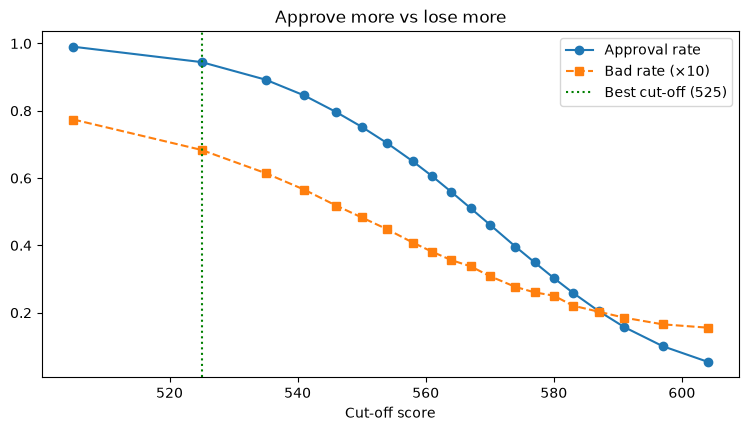

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cut["cutoff_score"], cut["approval_rate"], "o-", label="Approval rate")
ax.plot(cut["cutoff_score"], cut["bad_rate"] * 10, "s--", label="Bad rate (×10)")
ax.axvline(best.cutoff_score, ls=":", color="green", label=f"Best cut-off ({best.cutoff_score})")
ax.set(xlabel="Cut-off score", title="Approve more vs lose more")
ax.legend()
CHARTS.mkdir(parents=True, exist_ok=True)
plt.savefig(CHARTS / "01_cutoff_tradeoff.png", dpi=150)
plt.show()

In [23]:
ca = importlib.reload(ca)
el = ca.expected_loss_by_tier(test, lgd=LGD)
print(f"Expected loss rate: {el['expected_loss'].sum() / el['ead'].sum():.2%}")
el

Expected loss rate: 4.54%


,risk_tier,avg_pd,ead,expected_loss,share_of_book,share_of_loss
0,A,0.0213,"10,317,733,807.5000","130,665,658.3223",0.2243,0.0625
1,B,0.0390,"9,575,782,960.5000","223,294,019.9530",0.2082,0.1069
2,C,0.0592,"9,217,169,284.5000","326,706,347.9983",0.2004,0.1563
3,D,0.0918,"8,767,163,326.5000","481,971,270.1496",0.1906,0.2306
4,E,0.1928,"8,126,043,295.5000","927,134,404.4272",0.1766,0.4437


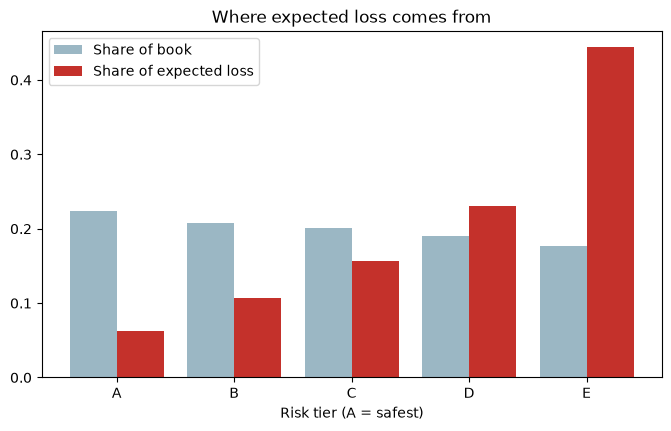

In [24]:
x = np.arange(len(el))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.2, el["share_of_book"], 0.4, label="Share of book", color="#9bb7c4")
ax.bar(x + 0.2, el["share_of_loss"], 0.4, label="Share of expected loss", color="#c4312b")
ax.set_xticks(x, el["risk_tier"])
ax.set(xlabel="Risk tier (A = safest)", title="Where expected loss comes from")
ax.legend()
plt.savefig(CHARTS / "01_expected_loss_by_tier.png", dpi=150)
plt.show()

In [26]:
ca = importlib.reload(ca)
aff = ca.affordability_table(df)
aff

,repayment_to_income,loans,bad_rate,share_of_loans
0,<10%,57210,0.0718,0.1860
1,10-15%,78018,0.0773,0.2537
2,15-20%,67213,0.0844,0.2186
3,20-25%,45919,0.0865,0.1493
4,25-30%,27823,0.0895,0.0905
5,30-40%,23407,0.0813,0.0761
6,40%+,7909,0.0827,0.0257


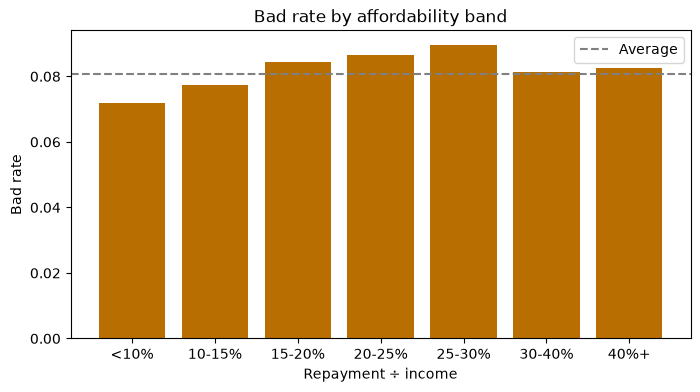

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(aff["repayment_to_income"].astype(str), aff["bad_rate"], color="#b86e00")
ax.axhline(df["TARGET"].mean(), ls="--", color="grey", label="Average")
ax.set(xlabel="Repayment ÷ income", ylabel="Bad rate", title="Bad rate by affordability band")
ax.legend()
plt.savefig(CHARTS / "01_affordability.png", dpi=150)
plt.show()

In [28]:
import json
OUT.mkdir(parents=True, exist_ok=True)
test[["SK_ID_CURR", "TARGET", "pd", "score", "risk_tier", "AMT_CREDIT"]].to_csv(OUT / "scored_holdout.csv.gz", index=False)
cut.to_csv(OUT / "cutoff_table.csv", index=False)
el.to_csv(OUT / "expected_loss_by_tier.csv", index=False)
aff.to_csv(OUT / "affordability.csv", index=False)
ca.coefficient_table(model).to_csv(OUT / "pd_model_coefficients.csv", index=False)
summary = {**metrics, "applications": len(df), "default_rate": float(df["TARGET"].mean()),
           "lgd": LGD, "margin_rate": MARGIN, "best_cutoff": int(best.cutoff_score),
           "best_approval_rate": float(best.approval_rate), "best_bad_rate": float(best.bad_rate)}
json.dump(summary, open(OUT / "model_summary.json", "w"), indent=2)
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['.gitkeep', 'affordability.csv', 'cutoff_table.csv', 'expected_loss_by_tier.csv', 'model_summary.json', 'pd_model_coefficients.csv', 'scored_holdout.csv.gz']
